# A/B Test Analysis: E-Commerce Pricing Strategy

**Project type:** Statistical Analysis / Hypothesis Testing  
**Tools:** Python, Pandas, NumPy, SciPy, Matplotlib, Seaborn

## Objective
Evaluate whether a new e-commerce pricing/landing page improves conversion compared with the existing page.

- **Control:** old pricing page
- **Treatment:** new pricing page
- **Significance level:** α = 0.05

Three complementary methods are used: Welch independent t-test, chi-square test of independence, and one-way ANOVA.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]=(9,5)
plt.rcParams["figure.dpi"]=110
pd.set_option("display.float_format", lambda x:f"{x:,.4f}")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Datasets

`ab_data.csv` contains user ID, timestamp, group, landing page and conversion. `countries.csv` maps users to CA, UK or US.

In [2]:
ab=pd.read_csv("../data/ab_data.csv")
countries=pd.read_csv("../data/countries.csv")
print("A/B dataset shape:",ab.shape)
print("Country dataset shape:",countries.shape)
display(ab.head())
display(countries.head())

A/B dataset shape: (294478, 5)
Country dataset shape: (290584, 2)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


,user_id,country
0,834778,UK
1,928468,US
2,822059,UK
3,711597,UK
4,710616,UK


## 3. Initial Data Inspection

In [3]:
print("Columns:",ab.columns.tolist())
print("\nMissing values:")
display(ab.isna().sum().to_frame("missing"))
print("\nGroup counts:")
display(ab["group"].value_counts().to_frame("users"))
print("\nLanding-page counts:")
display(ab["landing_page"].value_counts().to_frame("users"))

Columns: ['user_id', 'timestamp', 'group', 'landing_page', 'converted']

Missing values:


,missing
user_id,0
timestamp,0
group,0
landing_page,0
converted,0



Group counts:


,users
group,
treatment,147276
control,147202



Landing-page counts:


,users
landing_page,
old_page,147239
new_page,147239


## 4. Data Cleaning

A valid experiment should map control→old page and treatment→new page. Mismatches are removed. Duplicate user IDs are reduced to the first recorded visit, then country information is merged.

In [4]:
valid=((ab.group.eq("control")&ab.landing_page.eq("old_page"))|(ab.group.eq("treatment")&ab.landing_page.eq("new_page")))
mismatch_count=(~valid).sum()
duplicate_ids=ab.loc[ab.user_id.duplicated(keep=False),"user_id"].nunique()
clean=ab.loc[valid].copy().drop_duplicates("user_id",keep="first")
data=clean.merge(countries,on="user_id",how="inner")
print("Group/page mismatch rows removed:",mismatch_count)
print("Duplicate user IDs detected:",duplicate_ids)
print("Final rows after cleaning and merge:",len(data))
print("\nGroup sizes:"); display(data.group.value_counts().to_frame("users"))
print("\nCountry sizes:"); display(data.country.value_counts().to_frame("users"))

Group/page mismatch rows removed: 3893
Duplicate user IDs detected: 3894
Final rows after cleaning and merge: 290584

Group sizes:


,users
group,
treatment,145310
control,145274



Country sizes:


,users
country,
US,203619
UK,72466
CA,14499


## 5. Descriptive Conversion Analysis

In [5]:
group_summary=data.groupby("group").agg(users=("user_id","count"),conversions=("converted","sum"),conversion_rate=("converted","mean"))
group_summary["conversion_rate_pct"]=group_summary.conversion_rate*100
display(group_summary)
control_rate=group_summary.loc["control","conversion_rate"]
treatment_rate=group_summary.loc["treatment","conversion_rate"]
print(f"Control conversion rate: {control_rate*100:.3f}%")
print(f"Treatment conversion rate: {treatment_rate*100:.3f}%")
print(f"Treatment - Control: {(treatment_rate-control_rate)*100:.3f} percentage points")

,users,conversions,conversion_rate,conversion_rate_pct
group,,,,
control,145274,17489,0.1204,12.0386
treatment,145310,17264,0.1188,11.8808


Control conversion rate: 12.039%
Treatment conversion rate: 11.881%
Treatment - Control: -0.158 percentage points


### Conversion Rate by Pricing Strategy

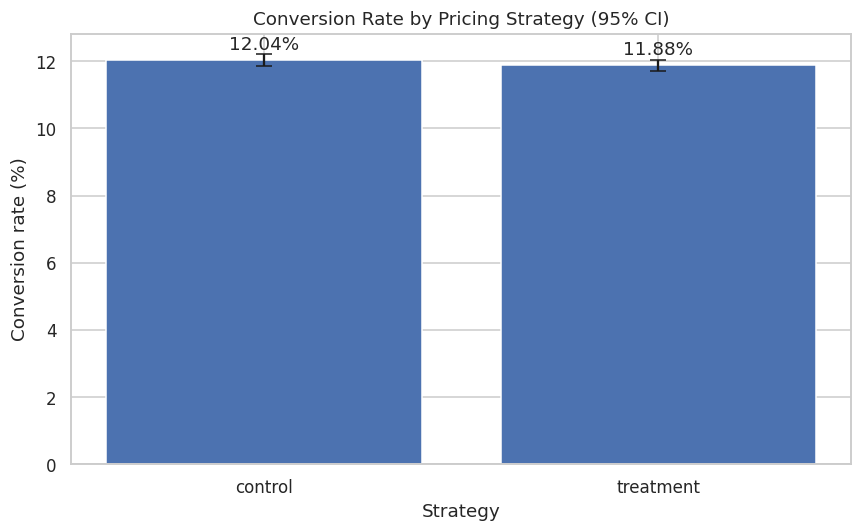

In [6]:
rows=[]
for g in ["control","treatment"]:
    x=data.loc[data.group.eq(g),"converted"]; p=x.mean(); se=np.sqrt(p*(1-p)/len(x)); rows.append([g,p*100,1.96*se*100])
pdplot=pd.DataFrame(rows,columns=["group","rate","ci"])
plt.figure(figsize=(8,5)); plt.bar(pdplot.group,pdplot.rate,yerr=pdplot.ci,capsize=5)
for _,r in pdplot.iterrows(): plt.text(r.group,r.rate+r.ci+.15,f"{r.rate:.2f}%",ha="center")
plt.title("Conversion Rate by Pricing Strategy (95% CI)"); plt.ylabel("Conversion rate (%)"); plt.xlabel("Strategy"); plt.tight_layout(); plt.show()

## 6. Test 1: Welch Independent Two-Sample t-Test

**H₀:** treatment mean = control mean  
**H₁:** treatment mean ≠ control mean

In [7]:
control=data.loc[data.group.eq("control"),"converted"]; treatment=data.loc[data.group.eq("treatment"),"converted"]
t_stat,t_p=stats.ttest_ind(treatment,control,equal_var=False)
n1,n0=len(treatment),len(control); m1,m0=treatment.mean(),control.mean(); v1,v0=treatment.var(ddof=1),control.var(ddof=1)
se=np.sqrt(v1/n1+v0/n0); df=(v1/n1+v0/n0)**2/((v1/n1)**2/(n1-1)+(v0/n0)**2/(n0-1)); crit=stats.t.ppf(.975,df)
ci=(m1-m0-crit*se,m1-m0+crit*se); pooled=np.sqrt(((n1-1)*v1+(n0-1)*v0)/(n1+n0-2)); d=(m1-m0)/pooled
res=pd.DataFrame({"Metric":["Control mean","Treatment mean","Difference","95% CI lower","95% CI upper","t-statistic","p-value","Cohen's d"],"Value":[m0,m1,m1-m0,ci[0],ci[1],t_stat,t_p,d]}); display(res); print("Decision:","Reject H0" if t_p<.05 else "Fail to reject H0")

,Metric,Value
0,Control mean,0.1204
1,Treatment mean,0.1188
2,Difference,-0.0016
3,95% CI lower,-0.0039
4,95% CI upper,0.0008
5,t-statistic,-1.3109
6,p-value,0.1899
7,Cohen's d,-0.0049


Decision: Fail to reject H0


## 7. Test 2: Chi-Square Test of Independence

**H₀:** strategy and conversion are independent  
**H₁:** strategy and conversion are related

In [8]:
table=pd.crosstab(data.group,data.converted); table.columns=["Not Converted","Converted"]; display(table)
chi2,chi_p,chi_df,expected=stats.chi2_contingency(table)
display(pd.DataFrame({"Metric":["Chi-square statistic","Degrees of freedom","p-value"],"Value":[chi2,chi_df,chi_p]})); print("Decision:","Reject H0" if chi_p<.05 else "Fail to reject H0")

,Not Converted,Converted
group,,
control,127785,17489
treatment,128046,17264


,Metric,Value
0,Chi-square statistic,1.7036
1,Degrees of freedom,1.0000
2,p-value,0.1918


Decision: Fail to reject H0


## 8. Test 3: One-Way ANOVA by Country

**H₀:** all country conversion means are equal  
**H₁:** at least one country mean differs

In [9]:
country_summary=data.groupby("country").agg(users=("user_id","count"),conversions=("converted","sum"),conversion_rate=("converted","mean")); country_summary["conversion_rate_pct"]=country_summary.conversion_rate*100; display(country_summary)
groups=[data.loc[data.country.eq(c),"converted"] for c in sorted(data.country.unique())]
anova_country=stats.f_oneway(*groups)
display(pd.DataFrame({"Comparison":["Conversion across 3 countries"],"F-statistic":[anova_country.statistic],"p-value":[anova_country.pvalue]})); print("Decision:","Reject H0" if anova_country.pvalue<.05 else "Fail to reject H0")

,users,conversions,conversion_rate,conversion_rate_pct
country,,,,
CA,14499,1672,0.1153,11.5318
UK,72466,8739,0.1206,12.0594
US,203619,24342,0.1195,11.9547


,Comparison,F-statistic,p-value
0,Conversion across 3 countries,1.6053,0.2008


Decision: Fail to reject H0


## 9. ANOVA by Country × Strategy

In [10]:
data["country_strategy"]=data.group+" - "+data.country
groups=[data.loc[data.country_strategy.eq(c),"converted"] for c in sorted(data.country_strategy.unique())]
anova_combo=stats.f_oneway(*groups)
combo=data.groupby(["country","group"]).agg(users=("user_id","count"),conversions=("converted","sum"),conversion_rate=("converted","mean")); combo["conversion_rate_pct"]=combo.conversion_rate*100; display(combo)
display(pd.DataFrame({"Comparison":["Conversion across 6 country × strategy groups"],"F-statistic":[anova_combo.statistic],"p-value":[anova_combo.pvalue]})); print("Decision:","Reject H0" if anova_combo.pvalue<.05 else "Fail to reject H0")

users  conversions  conversion_rate  conversion_rate_pct
country group                                                               
CA      control      7198          855           0.1188              11.8783
        treatment    7301          817           0.1119              11.1902
UK      control     36360         4364           0.1200              12.0022
        treatment   36106         4375           0.1212              12.1171
US      control    101716        12270           0.1206              12.0630
        treatment  101903        12072           0.1185              11.8466

,Comparison,F-statistic,p-value
0,Conversion across 6 country × strategy groups,1.4664,0.1971


Decision: Fail to reject H0


### Conversion Rate by Country and Strategy

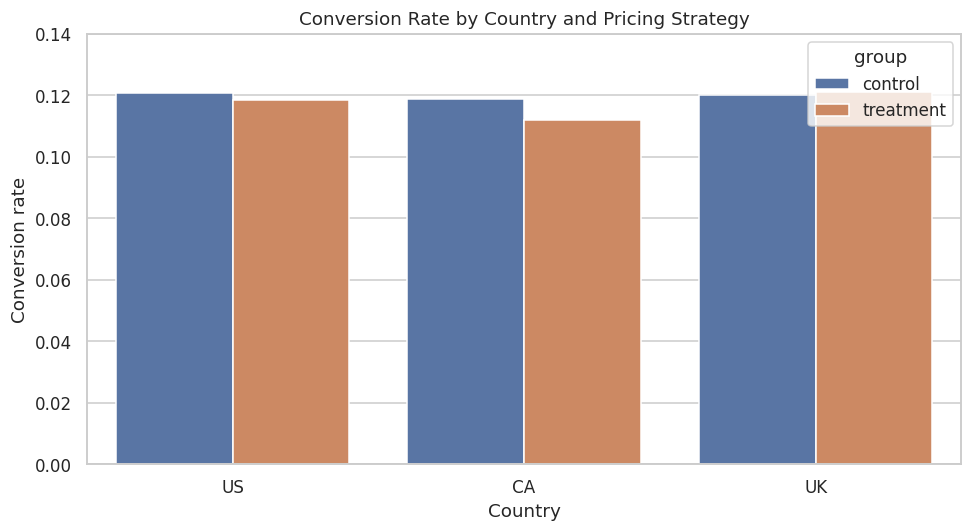

In [11]:
plt.figure(figsize=(9,5)); sns.barplot(data=data,x="country",y="converted",hue="group",errorbar=None); plt.ylim(0,.14); plt.title("Conversion Rate by Country and Pricing Strategy"); plt.xlabel("Country"); plt.ylabel("Conversion rate"); plt.tight_layout(); plt.show()

## 10. Statistical Test Summary

In [12]:
summary=pd.DataFrame({"Test":["Welch t-test","Chi-square","ANOVA: 3 countries","ANOVA: 6 country × strategy groups"],"Statistic":[t_stat,chi2,anova_country.statistic,anova_combo.statistic],"p-value":[t_p,chi_p,anova_country.pvalue,anova_combo.pvalue]}); summary["Decision"]=np.where(summary["p-value"]<.05,"Reject H0","Fail to reject H0"); display(summary)

,Test,Statistic,p-value,Decision
0,Welch t-test,-1.3109,0.1899,Fail to reject H0
1,Chi-square,1.7036,0.1918,Fail to reject H0
2,ANOVA: 3 countries,1.6053,0.2008,Fail to reject H0
3,ANOVA: 6 country × strategy groups,1.4664,0.1971,Fail to reject H0


## 11. Findings and Conclusion

- The control page has a slightly higher observed conversion rate than the treatment page.
- The difference is very small and is not statistically significant at α = 0.05.
- The Welch t-test and chi-square test agree that conversion is not significantly associated with pricing strategy.
- ANOVA finds no significant difference across countries and no hidden winning country/strategy combination.
- Failing to reject H₀ does not prove the pages are identical; it means this dataset does not provide sufficient evidence of a difference.

### Recommendation
Retain the existing pricing page based on this experiment. If the business expects a very small improvement, a longer or larger follow-up experiment could be designed specifically to detect that effect.

## 12. Export Cleaned Dataset

In [13]:
data.to_csv("../data/cleaned_ab_country_data.csv",index=False); print("Saved cleaned dataset with",len(data),"rows.")

Saved cleaned dataset with 290584 rows.
